# Marketing econometrics

Practical work: build a RFM segmentation

MASTER 2 TSE 

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)

# 1. Load the data

Import the 6 csv tables in a Jupyter notebook with Python 3 and look at the first rows of each table.

In [3]:
mypath = "Data"

In [4]:
CUSTOMER = pd.read_csv(mypath + "/CUSTOMER.csv")
CUSTOMER_ADDITIONAL = pd.read_csv(mypath + "/CUSTOMER_ADDITIONAL.csv")
PRODUCTS = pd.read_csv(mypath + "/PRODUCTS.csv")
RECEIPTS = pd.read_csv(mypath + "/RECEIPTS.csv")
REFERENTIAL = pd.read_csv(mypath + "/REFERENTIAL.csv", dtype = {'EAN': 'str'})
STORE = pd.read_csv(mypath + "/STORE.csv")

In [5]:
CUSTOMER.head()

,ID_INDIVIDU,ID_FOYER,CIVILITE,SEXE,PROFESSION,CATEGORIE_PROF,DATE_NAISS_A,DATE_NAISS_M,DATE_NAISS_J,DATE_CREATION_CARTE
0,4,175898,0,0,NaN,NaN,NaN,NaN,NaN,01/01/1989
1,27,0,3,2,NaN,3.0,1967.0,9.0,1.0,08/08/2007
2,34,127060,3,2,NaN,6.0,1953.0,3.0,4.0,27/07/2007
3,37,0,2,2,NaN,3.0,1964.0,8.0,21.0,11/07/2007
4,47,0,3,2,NaN,NaN,1972.0,3.0,31.0,23/04/2008


In [6]:
CUSTOMER_ADDITIONAL.head()

,ID_INDIVIDU,CODE_MAGASIN,PAYS,ETAT,TAILLE,TAILLE_SG,TAILLE_BONNET
0,4,751,FR,N,38.0,95.0,B
1,27,942,FR,N,38.0,85.0,B
2,34,942,FR,N,42.0,95.0,B
3,37,942,FR,N,42.0,90.0,B
4,47,941,FR,N,40.0,90.0,C


In [7]:
PRODUCTS.head()

,Ligne,Famille,Libelle_modele,MODELE
0,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100
1,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100B
2,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100C
3,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100D
4,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100E


In [8]:
RECEIPTS.head()

,DATE_ACHAT,EAN,ID_INDIVIDU,ID_FOYER,CODE_LIGNE,TYPE_LIGNE,NUM_TICKET,QUANTITE,PRIX_AP_REMISE,REMISE,REMISE_VALEUR,CODE_BOUTIQUE
0,"""14/12/2013""",3585211297939,4,0,81,"""SALE""",29,1,28,0,0,756
1,"""14/12/2015""",3585211731150,4,175898,81,"""SALE""",10,1,69,0,0,730
2,"""14/12/2013""",3585210149062,4,0,81,"""SALE""",29,1,0,0,100,756
3,"""14/12/2013""",3585211405723,4,0,81,"""SALE""",29,1,23,0,0,756
4,"""02/07/2016""",3585211668319,4,175898,81,"""SALE""",513,1,75,0,0,920


In [9]:
REFERENTIAL.head()

,ID_ARTICLE,ID_MODELE,ID_OPTION,MODELE,OPTION_PTT,COLORIS,POSITION,GRILLE,EAN
0,42915,31,964,247,CONFE,10,6,10,NaN
1,42916,31,964,247,CONFE,36,1,10,NaN
2,42917,31,964,247,CONFE,36,2,10,NaN
3,42918,31,964,247,CONFE,36,3,10,NaN
4,42919,31,964,247,CONFE,36,6,10,NaN


In [10]:
STORE.head()

,CODE_BOUTIQUE,ID_BOUTIQUE,REGIONS,VILLE,CDP,CENTRE_VILLE,CONCEP,TYPE_MAGASIN,MER_TERRE,REGIONS_COMMERCIAL,QUOTA
0,61,44,Province,Nice,0 6000,Centre Co,ac,mag propre,mer,NaN,150.0
1,62,72,Province,CAP 3000,06700,Centre Commercial,nc,Succursale,Mer,Province,0.0
2,63,75,Province,CANNES,06400,Centre ville,nc,Succursale,Mer,Province,0.0
3,121,106,Province,RODEZ,12000,Centre ville,nv,Affilié,Mer,Province,0.0
4,130,38,Province,MARSEILLE,13001,Centre ville,ac,Succursale,Mer,Province,150.0


# 2 Selection and merging of the data

## 2.1 Build the CUSTOMERS_INFO table containing all the information about a customer

### 2.1.1 Join the CUSTOMER’s dimensions (CUSTOMER and CUSTOMER_ADDITIONAL) in a table called CUSTOMER_INFO

To be able to do this join, you need to answer two questions:
  
- What kind of column should you use to make the merge? We are trying to find additional customer information to the main table of customers. Which column-s can help us identify matching information?

- What kind of merge should you perform? Reminder: use `how = _` with `_` being either inner / left / right / outer. To answer this, ask yourself: do we want to keep only rows present in both datasets (inner)? All rows from the 1st dataset (left)? All rows from the 2nd dataset (right)? All rows of both datasets (outer)? We will always use the same kind of merge throughout the project so make sure you use the good one. A clue: the 1st dataset is the most important one so we don't to lose any information about it.

Ask the teacher to check whether you used the good type of join.

In [11]:
CUSTOMERS_INFO = CUSTOMER.merge(
    CUSTOMER_ADDITIONAL,
    on = 'ID_INDIVIDU',
    how = 'left'
)

In [12]:
CUSTOMERS_INFO.head()

,ID_INDIVIDU,ID_FOYER,CIVILITE,SEXE,PROFESSION,CATEGORIE_PROF,DATE_NAISS_A,DATE_NAISS_M,DATE_NAISS_J,DATE_CREATION_CARTE,CODE_MAGASIN,PAYS,ETAT,TAILLE,TAILLE_SG,TAILLE_BONNET
0,4,175898,0,0,NaN,NaN,NaN,NaN,NaN,01/01/1989,751,FR,N,38.0,95.0,B
1,27,0,3,2,NaN,3.0,1967.0,9.0,1.0,08/08/2007,942,FR,N,38.0,85.0,B
2,34,127060,3,2,NaN,6.0,1953.0,3.0,4.0,27/07/2007,942,FR,N,42.0,95.0,B
3,37,0,2,2,NaN,3.0,1964.0,8.0,21.0,11/07/2007,942,FR,N,42.0,90.0,B
4,47,0,3,2,NaN,NaN,1972.0,3.0,31.0,23/04/2008,941,FR,N,40.0,90.0,C


- Make sure all three tables have same number of rows.

In [13]:
print('CUSTOMER           :', CUSTOMER.shape[0], 'lignes et', CUSTOMER.shape[1], 'colonnes.')
print('CUSTOMER_ADDITIONAL:', CUSTOMER_ADDITIONAL.shape[0], 'lignes et', CUSTOMER_ADDITIONAL.shape[1], 'colonnes.')
print('CUSTOMERS_INFO     :', CUSTOMERS_INFO.shape[0], 'lignes et', CUSTOMERS_INFO.shape[1], 'colonnes.')

CUSTOMER           : 36157 lignes et 10 colonnes.
CUSTOMER_ADDITIONAL: 36157 lignes et 7 colonnes.
CUSTOMERS_INFO     : 36157 lignes et 16 colonnes.


The dimensions of the 3 tables are consistent: we have the same number of rows and the final table contains all the selected columns from the 2 tables, minus the column(s) used for merging.

- Rename CODE_MAGASIN in MANAGING_STORE

In [14]:
CUSTOMERS_INFO.rename(columns = {'CODE_MAGASIN': 'MANAGING_STORE'}, inplace = True)

In [15]:
CUSTOMERS_INFO.head()

,ID_INDIVIDU,ID_FOYER,CIVILITE,SEXE,PROFESSION,CATEGORIE_PROF,DATE_NAISS_A,DATE_NAISS_M,DATE_NAISS_J,DATE_CREATION_CARTE,MANAGING_STORE,PAYS,ETAT,TAILLE,TAILLE_SG,TAILLE_BONNET
0,4,175898,0,0,NaN,NaN,NaN,NaN,NaN,01/01/1989,751,FR,N,38.0,95.0,B
1,27,0,3,2,NaN,3.0,1967.0,9.0,1.0,08/08/2007,942,FR,N,38.0,85.0,B
2,34,127060,3,2,NaN,6.0,1953.0,3.0,4.0,27/07/2007,942,FR,N,42.0,95.0,B
3,37,0,2,2,NaN,3.0,1964.0,8.0,21.0,11/07/2007,942,FR,N,42.0,90.0,B
4,47,0,3,2,NaN,NaN,1972.0,3.0,31.0,23/04/2008,941,FR,N,40.0,90.0,C


## 2.2 Build the RECEIPTS_INFO table containing all the information about a receipt

### 2.2.1 Join the RECEIPTS’s dimensions (STORE, REFERENTIAL, PRODUCTS and RECEIPTS) in a table called RECEIPTS_INFO

- Start with the join of RECEIPTS and REFERENTIAL. Remove comments from the lines to run the code.

In [16]:
# Cette jointure échoue : EAN est un int64 dans RECEIPTS et un str dans REFERENTIAL
# RECEIPTS_INFO = RECEIPTS.merge(
#     REFERENTIAL,
#     on = 'EAN',
#     how = 'left'
# )

As the Python error says, merging means columns used need to be in the same Python format. We can see this is not the case:

In [17]:
RECEIPTS.dtypes

DATE_ACHAT        object
EAN                int64
ID_INDIVIDU        int64
ID_FOYER           int64
CODE_LIGNE         int64
TYPE_LIGNE        object
NUM_TICKET         int64
QUANTITE           int64
PRIX_AP_REMISE     int64
REMISE             int64
REMISE_VALEUR      int64
CODE_BOUTIQUE      int64
dtype: object

In [18]:
REFERENTIAL.dtypes

ID_ARTICLE     int64
ID_MODELE      int64
ID_OPTION      int64
MODELE        object
OPTION_PTT    object
COLORIS        int64
POSITION       int64
GRILLE         int64
EAN           object
dtype: object

We decide to convert the type of `EAN`. Note: do not use `object` type, but `str`!

In [19]:
RECEIPTS['EAN'] = RECEIPTS['EAN'].astype(str)

Create RECEIPTS_INFO merging tables RECEIPTS and REFERENTIAL:

In [20]:
RECEIPTS_INFO = RECEIPTS.merge(
    REFERENTIAL,
    on = 'EAN',
    how = 'left'
)

In [21]:
print('RECEIPTS     :', RECEIPTS.shape[0], 'lignes et', RECEIPTS.shape[1], 'colonnes.')
print('REFERENTIAL  :', REFERENTIAL.shape[0], 'lignes et', REFERENTIAL.shape[1], 'colonnes.')
print('RECEIPTS_INFO:', RECEIPTS_INFO.shape[0], 'lignes et', RECEIPTS_INFO.shape[1], 'colonnes.')

RECEIPTS     : 332736 lignes et 12 colonnes.
REFERENTIAL  : 66661 lignes et 9 colonnes.
RECEIPTS_INFO: 332736 lignes et 20 colonnes.


The dimensions of the 3 tables are consistent: we have the same number of rows in the left and final table, and the final table contains all the columns of the two initial tables.

If this is not the case, you did not pick the correct `how` method for merging!

- Now we will walk through the join of PRODUCTS with the table created above. 

In [22]:
PRODUCTS.head()

,Ligne,Famille,Libelle_modele,MODELE
0,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100
1,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100B
2,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100C
3,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100D
4,Corseterie,Emboitant,SOUTIEN GORGE ARMATURE,100E


Keep only Ligne and Famille from PRODUCTS (and obviously the column needed for the merge). Merge this DataFrame with recently created RECEIPTS_INFO.

In [23]:
RECEIPTS_FULL = RECEIPTS_INFO.merge(
    PRODUCTS[['MODELE', 'Ligne', 'Famille']],
    on = 'MODELE',
    how = 'left'
)

In [24]:
print('RECEIPTS_INFO:', RECEIPTS_INFO.shape[0], 'lignes et', RECEIPTS_INFO.shape[1], 'colonnes.')
print('PRODUCTS     :', PRODUCTS.shape[0], 'lignes et', PRODUCTS.shape[1], 'colonnes.')
print('RECEIPTS_FULL:', RECEIPTS_FULL.shape[0], 'lignes et', RECEIPTS_FULL.shape[1], 'colonnes.')

RECEIPTS_INFO: 332736 lignes et 20 colonnes.
PRODUCTS     : 206 lignes et 4 colonnes.
RECEIPTS_FULL: 332736 lignes et 22 colonnes.


Check: 1st table RECEIPTS_INFO and RECEIPTS_FULL should have the same number of rows.

- Now the join of STORE with the table created above.

Keep only REGIONS, CENTRE_VILLE, TYPE_MAGASIN, REGIONS_COMMERCIAL from STORE, and the variable for the merge.

Merge this DataFrame with previously created RECEIPTS_FULL.

In [25]:
STORE.columns

Index(['CODE_BOUTIQUE', 'ID_BOUTIQUE', 'REGIONS', 'VILLE', 'CDP',
       'CENTRE_VILLE', 'CONCEP', 'TYPE_MAGASIN', 'MER_TERRE',
       'REGIONS_COMMERCIAL', 'QUOTA'],
      dtype='object')

In [26]:
RECEIPTS_FINAL = RECEIPTS_FULL.merge(
    STORE[['CODE_BOUTIQUE', 'REGIONS', 'CENTRE_VILLE', 'TYPE_MAGASIN', 'REGIONS_COMMERCIAL']],
    on = 'CODE_BOUTIQUE',
    how = 'left'
)

In [27]:
print('RECEIPTS_FULL:', RECEIPTS_FULL.shape[0], 'lignes et', RECEIPTS_FULL.shape[1], 'colonnes.')
print('STORE        :', STORE.shape[0], 'lignes et', STORE.shape[1], 'colonnes.')
print('RECEIPTS_FINAL:', RECEIPTS_FINAL.shape[0], 'lignes et', RECEIPTS_FINAL.shape[1], 'colonnes.')

RECEIPTS_FULL: 332736 lignes et 22 colonnes.
STORE        : 113 lignes et 11 colonnes.
RECEIPTS_FINAL: 332736 lignes et 26 colonnes.


Finally we have 

- a CUSTOMERS_INFO table with 36157 rows and 16 columns, and 
- a RECEIPTS_FINAL table with 332736 rows and 26 columns.

# 3 Understanding the data

## 3.1 Identifying a visit

Before starting the audit of a database, it is important to understand how the different types of data are linked. It is mandatory to define a way to uniquely identify "customer actions." Since we are interested in stores purchases, we need to consider:

- 1 unique visit by 1 given person in 1 given store on 1 given date, defined as 1 purchase receipt.
- If 1 person visited twice 1 store on 1 given date, we need to identify 2 different receipts.
- If 2 persons visited 1 given store on 1 given date, we need to identify 2 different receipts.
- If 1 person visited 2 given stores on 1 given date, we need to identify 2 different receipts.

Deduce from the analysis of the columns in `RECEIPTS_FINAL` and the hypotheses above the columns needed to identify 1 store visit, that means 1 unique purchase receipt.

It seems like we need to use the information `NUM_TICKET`. However, is it enough? Can we use other variables to make sure we only consider unique visits, ie. unique purchase tickets?

Clue: you should use 4 columns.

**Réponse :** une visite (un ticket) est identifiée par les 4 colonnes `ID_INDIVIDU`, `CODE_BOUTIQUE`, `DATE_ACHAT` et `NUM_TICKET`. `NUM_TICKET` seul ne suffit pas : il repart à 1 et se répète entre boutiques et entre dates. Sur la période d'étude, cette clé donne 30 921 visites.

## 3.2 Audit and analysis of the consistency of variables

### 3.2.1 Analyze variables in RECEIPTS_INFO

We will analyze some columns with some specific questions.

There are other columns that we won't analyze now, but that can be mentioned in the oral presentation (not mandatory !)

- There are many different ways to analyze a dataset, but we can take a quick glance at the data with the `describe` pandas function:

In [28]:
RECEIPTS_FINAL.describe(include = 'all')

,DATE_ACHAT,EAN,ID_INDIVIDU,ID_FOYER,CODE_LIGNE,TYPE_LIGNE,NUM_TICKET,QUANTITE,PRIX_AP_REMISE,REMISE,REMISE_VALEUR,CODE_BOUTIQUE,ID_ARTICLE,ID_MODELE,ID_OPTION,MODELE,OPTION_PTT,COLORIS,POSITION,GRILLE,Ligne,Famille,REGIONS,CENTRE_VILLE,TYPE_MAGASIN,REGIONS_COMMERCIAL
count,332736,332736,332736.000000,332736.000000,332736.0,332736,332736.000000,332736.000000,332736.000000,332736.000000,332736.000000,332736.000000,303499.000000,303499.000000,303499.000000,303499,303499,303499.000000,303499.000000,303499.000000,258795,258795,332731,332731,332731,330309
unique,1389,20652,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,242,394,NaN,NaN,NaN,3,15,2,3,3,2
top,"""10/01/2016""",3585211608377,NaN,NaN,NaN,"""SALE""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FAVO,FRIVO,NaN,NaN,NaN,Corseterie,String/Tanga,Province,Centre ville,Succursale,Province
freq,1445,5712,NaN,NaN,NaN,332736,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33954,34422,NaN,NaN,NaN,199068,44316,217044,237672,308969,214622
mean,NaN,NaN,147678.532506,144237.106099,81.0,NaN,23.567309,1.000192,27.121210,1.082194,17.396173,1059.833420,51896.532924,115.842948,6723.194561,NaN,NaN,805.029568,3.074544,11.636691,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,52637.530958,52313.255825,0.0,NaN,59.301186,0.021231,16.934751,6.299442,40.670952,1795.804301,10602.292905,110.780155,4981.945133,NaN,NaN,1935.815036,1.707014,8.816782,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,4.000000,0.000000,81.0,NaN,1.000000,1.000000,0.000000,-42.000000,0.000000,61.000000,49.000000,1.000000,49.000000,NaN,NaN,10.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,112105.000000,108836.000000,81.0,NaN,6.000000,1.000000,19.000000,0.000000,0.000000,342.000000,46662.000000,20.000000,1249.000000,NaN,NaN,13.000000,1.000000,4.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,152206.000000,148786.000000,81.0,NaN,12.000000,1.000000,28.000000,0.000000,0.000000,691.000000,52952.000000,96.000000,6349.000000,NaN,NaN,40.000000,3.000000,10.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,187926.000000,184303.000000,81.0,NaN,22.000000,1.000000,39.000000,0.000000,0.000000,781.000000,59991.000000,178.000000,11424.000000,NaN,NaN,70.000000,5.000000,25.000000,NaN,NaN,NaN,NaN,NaN,NaN


- Analyze together `REGIONS` and `REGIONS_COMMERCIAL`. Is there a column that does not provide additional information and can be removed?

In [29]:
RECEIPTS_FINAL.groupby(['REGIONS','REGIONS_COMMERCIAL'], dropna = False)['EAN'].count()

REGIONS   REGIONS_COMMERCIAL
Paris     Paris                 115687
Province  Province              214622
          NaN                     2422
NaN       NaN                        5
Name: EAN, dtype: int64

In [30]:
pd.crosstab(RECEIPTS_FINAL['REGIONS'], RECEIPTS_FINAL['REGIONS_COMMERCIAL'], dropna = False)

REGIONS_COMMERCIAL,Paris,Province,NaN
REGIONS,,,
Paris,115687,0,0
Province,0,214622,2422
NaN,0,0,5


`REGIONS_COMMERCIAL` n'apporte aucune information supplémentaire : elle est identique à `REGIONS`, sauf pour 2 422 lignes où elle est manquante (boutique 61, Nice). On la supprime et on garde `REGIONS`.

In [31]:
RECEIPTS_FINAL = RECEIPTS_FINAL.drop(columns = ['REGIONS_COMMERCIAL'])

- Analyze `CENTRE_VILLE`. Is there a modality that can be modified?

La modalité `Centre Co` (2 422 lignes, boutique 61 à Nice) est une abréviation de `Centre Commercial` : on regroupe les deux.

In [32]:
RECEIPTS_FINAL['CENTRE_VILLE'].value_counts()

CENTRE_VILLE
Centre ville         237672
Centre Commercial     92637
Centre Co              2422
Name: count, dtype: int64

In [33]:
RECEIPTS_FINAL['CENTRE_VILLE'] = RECEIPTS_FINAL['CENTRE_VILLE'].replace({'Centre Co': 'Centre Commercial'})
RECEIPTS_FINAL['CENTRE_VILLE'].value_counts()

CENTRE_VILLE
Centre ville         237672
Centre Commercial     95059
Name: count, dtype: int64

- Analyse together `Ligne` and `Famille` just to get a grasp of the product's hierarchy. There shouldn't be any modification to be done.

In [34]:
RECEIPTS_FINAL.groupby(['Ligne', 'Famille'], dropna = False)['EAN'].count()

Ligne       Famille                 
Bain        Bain_Beachwear               8365
            Bain_Maillot                21653
            Push-up                         2
            Triangle/Brassiere            392
Corseterie  Bustier/Guepiere              145
            Corbeille                   13811
            Corbeille mousse/Bandeau     9902
            Corseterie_PP               12875
            Emboitant                   16734
            Push-up                     20188
            Short                       25877
            Slip                        40817
            String/Tanga                44316
            Triangle/Brassiere          14403
Homewear    Homewear_Bas                 9061
            Homewear_Ensemble            8421
            Homewear_Haut               11833
NaN         NaN                         73941
Name: EAN, dtype: int64

- Analyze `CODE_LIGNE` and `TYPE_LIGNE`. Are these columns useful?

In [35]:
RECEIPTS_FINAL.groupby(['CODE_LIGNE', 'TYPE_LIGNE'], dropna = False)['EAN'].count()
# Une seule modalité (81 / "SALE") sur toutes les lignes : ces colonnes n'apportent rien, on les supprime

CODE_LIGNE  TYPE_LIGNE
81          "SALE"        332736
Name: EAN, dtype: int64

In [36]:
RECEIPTS_FINAL = RECEIPTS_FINAL.drop(columns = ['CODE_LIGNE', 'TYPE_LIGNE'])

- Now for prices related variables:

In [37]:
RECEIPTS_FINAL[['PRIX_AP_REMISE','REMISE_VALEUR','REMISE']].head()

,PRIX_AP_REMISE,REMISE_VALEUR,REMISE
0,28,0,0
1,69,0,0
2,0,100,0
3,23,0,0
4,75,0,0


In [38]:
def compute_remise_value(row):
    if row['REMISE'] == 0 and row['REMISE_VALEUR'] == 100:
        return row['PRIX_AP_REMISE']
    elif row['REMISE'] == 0 and row['REMISE_VALEUR'] != 0:
        return row['PRIX_AP_REMISE'] / (100 / row['REMISE_VALEUR'] - 1)
    else:
        return row['REMISE']

def compute_remise_pct(row):
    if row['REMISE_VALEUR'] in (0, 100):
        return row['REMISE_VALEUR']
    elif row['PRIX_INITIAL'] != 0:
        return 100 * row['REMISE_VALUE'] / row['PRIX_INITIAL']
    else:
        return np.nan

RECEIPTS_FINAL['REMISE_VALEUR'] = np.where(RECEIPTS_FINAL['PRIX_AP_REMISE'] == 0, 100, RECEIPTS_FINAL['REMISE_VALEUR'])

RECEIPTS_FINAL['REMISE_VALUE'] = RECEIPTS_FINAL.apply(compute_remise_value, axis = 1)

RECEIPTS_FINAL['PRIX_INITIAL'] = RECEIPTS_FINAL['PRIX_AP_REMISE'] + RECEIPTS_FINAL['REMISE_VALUE']

RECEIPTS_FINAL['REMISE_PCT'] = RECEIPTS_FINAL.apply(compute_remise_pct, axis = 1)

- With some analysis on PRIX_AP_REMISE, REMISE_VALEUR, REMISE (exercise left to the reader!), we see:
  - If REMISE_VALEUR = 100 (100% ?), then PRIX_AP_REMISE is = 0,
  - If REMISE_VALEUR = 0, then REMISE = 0: there is no discount.

- So we suppose that:
  - PRIX_AP_REMISE is the price paid after potential discounts,
  - REMISE_VALEUR seems more useful than REMISE,
  - REMISE_VALEUR is the discount represented as a % (between 0 and 100 with some anomalies). If it equals 100% (total discount), price is null.
  
Then you should:
  - for `REMISE_VALEUR`, replace values by 100 if `PRIX_AP_REMISE` = 0
  - compute the real remise in value, name this column `REMISE_VALUE`:
    - if `REMISE` = 0 and `REMISE_VALEUR` = 100, it means the discount was 100% but we don't know the value: we set `REMISE_VALUE` to `PRIX_AP_REMISE`
    - if `REMISE` = 0 and `REMISE_VALEUR` is different from 0, we don't know the value but the % can help us: we set `REMISE_VALUE` to `PRIX_AP_REMISE` / (100 / `REMISE_VALEUR` - 1)
    - else, we know the value of the discount: we set `REMISE_VALUE` to `REMISE`


  - compute initial price as `PRIX_INITIAL` = `PRIX_AP_REMISE` + `REMISE_VALUE` created above
    
  - compute corrected discount in % as:
    - 0 or 100 if `REMISE_VALEUR` is 0 or 100
    - `REMISE_VALUE` / `PRIX_INITIAL` othervise


Hypotheses have been taken here, feel free to refute them in your presentation!

**Remarque :** 7 lignes ont un `REMISE_VALEUR` supérieur à 100 (anomalie de saisie). 5 ont un prix nul et sont recodées à 100 %, 1 a une `REMISE` renseignée (utilisée telle quelle), et une seule (prix 48 €, `REMISE_VALEUR` = 177) donne une `REMISE_VALUE` négative (≈ −110 €). Sans impact sur le RFM, calculé sur `PRIX_AP_REMISE`.

In [39]:
RECEIPTS_FINAL = RECEIPTS_FINAL.drop(columns = ['REMISE','REMISE_VALEUR'])

- Analyzing data and speaking with the marketing team, you need to create new variables:
  - a column called `Favorites` identifying products custom built for a specific customer, often gifted to high value customers (`MODELE` should be equal to FAVO or FAVORI)
  - a column called `Access` identifying affordable entry-level products to build awareness of the brand and acquire new customers (`MODELE` should be equal to ACCESS)
  - a column called `PLV` (Publicité en Lieu de Vente) identifying products where `MODELE` is equal to PLV (free products given in stores to customers, that can also be sold during specific events)
  - a column called `Gift` identifying... gifts: when `PRIX_AP_REMISE` = 0.

In [40]:
RECEIPTS_FINAL['Favorites'] = RECEIPTS_FINAL['MODELE'].isin(['FAVO', 'FAVORI']).astype(int)

In [41]:
RECEIPTS_FINAL['Access'] = (RECEIPTS_FINAL['MODELE'] == 'ACCESS').astype(int)

In [42]:
RECEIPTS_FINAL['PLV'] = (RECEIPTS_FINAL['MODELE'] == 'PLV').astype(int)

In [43]:
RECEIPTS_FINAL['Gift'] = (RECEIPTS_FINAL['PRIX_AP_REMISE'] == 0).astype(int)

# 4 Data preparation: cleaning and creation of indicators


## 4.1 Data preparation of RECEIPTS_INFO

### 4.1.1 Handle DATE_ACHAT

- Find columns that should be stored as dates. Convert them to Pandas date type (hint: `pd.to_datetime()` should prove useful, with appropriate format: %d is for days, %m for months, %Y for years, where delimiters are often `-`, `\`, ...). Be careful and look at some dates, there should be something that bothers you when looking at the first and last characters of the column. Use that information in the `format` argument for the `pd.to_datetime()` function. See https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html.

In [44]:
RECEIPTS_INFO_OK = RECEIPTS_FINAL.copy()

In [45]:
RECEIPTS_INFO_OK["DATE_ACHAT"] = pd.to_datetime(RECEIPTS_INFO_OK["DATE_ACHAT"], format = '"%d/%m/%Y"')

### 4.1.3 Compute Price

- Compute the final price of a purchase with `PRIX_AP_REMISE` x `QUANTITE`.

In [46]:
RECEIPTS_INFO_OK["PRICE"] = RECEIPTS_INFO_OK["PRIX_AP_REMISE"] * RECEIPTS_INFO_OK["QUANTITE"]

In [47]:
RECEIPTS_INFO_OK.head()

,DATE_ACHAT,EAN,ID_INDIVIDU,ID_FOYER,NUM_TICKET,QUANTITE,PRIX_AP_REMISE,CODE_BOUTIQUE,ID_ARTICLE,ID_MODELE,ID_OPTION,MODELE,OPTION_PTT,COLORIS,POSITION,GRILLE,Ligne,Famille,REGIONS,CENTRE_VILLE,TYPE_MAGASIN,REMISE_VALUE,PRIX_INITIAL,REMISE_PCT,Favorites,Access,PLV,Gift,PRICE
0,2013-12-14,3585211297939,4,0,29,1,28,756,41656.0,21.0,1249.0,128,PROME,10.0,2.0,10.0,Corseterie,String/Tanga,Paris,Centre ville,Succursale,0.0,28.0,0.0,0,0,0,0,28
1,2015-12-14,3585211731150,4,175898,10,1,69,730,60020.0,116.0,12128.0,222,MERVE,41.0,4.0,3.0,Homewear,Homewear_Ensemble,Province,Centre ville,Affilié,0.0,69.0,0.0,0,0,0,0,69
2,2013-12-14,3585210149062,4,0,29,1,0,756,150.0,7.0,136.0,FAVORI,AGEND,13.0,1.0,5.0,NaN,NaN,Paris,Centre ville,Succursale,0.0,0.0,100.0,1,0,0,1,0
3,2013-12-14,3585211405723,4,0,29,1,23,756,45761.0,19.0,3056.0,122,SULFU,93.0,1.0,10.0,Corseterie,String/Tanga,Paris,Centre ville,Succursale,0.0,23.0,0.0,0,0,0,0,23
4,2016-07-02,3585211668319,4,175898,513,1,75,920,54398.0,136.0,8251.0,503,CAPFE,20.0,4.0,3.0,Bain,Bain_Maillot,Paris,Centre Commercial,Succursale,0.0,75.0,0.0,0,0,0,0,75


### 4.1.5 Indicators calculation - scope

Filter on the last 12 months available, taking complete months.

**VERY IMPORTANT**: we are filtering on RECEIPTS information. All future computations regarding receipts will be performed with this date perimeter!

It should result in **119 215 rows**.

In [48]:
RECEIPTS_INFO_OK["DATE_ACHAT"].min()

Timestamp('2012-09-01 00:00:00')

In [49]:
RECEIPTS_INFO_OK["DATE_ACHAT"].max()

Timestamp('2016-08-31 00:00:00')

In [50]:
min_date_RFM = pd.Timestamp('2015-09-01')
max_date_RFM = pd.Timestamp('2016-08-31')

In [51]:
RECEIPTS_INFO_RFM = RECEIPTS_INFO_OK[
    (RECEIPTS_INFO_OK.DATE_ACHAT >= min_date_RFM) 
    & (RECEIPTS_INFO_OK.DATE_ACHAT <= max_date_RFM)
]

In [52]:
RECEIPTS_INFO_RFM.DATE_ACHAT.min()

Timestamp('2015-09-01 00:00:00')

In [53]:
RECEIPTS_INFO_RFM.DATE_ACHAT.max()

Timestamp('2016-08-31 00:00:00')

In [54]:
RECEIPTS_INFO_RFM.shape

(119215, 29)

### 4.1.6 Compute Monetary Value per visit and the Average Price

For each visit (see 3.1 to properly identify 1 visit), compute:
- the number of products sold (you can call it `NB_PRODUCTS`)
- the monetary value (sum of the products prices ; you can call it `MONETARY_VALUE`).

Average price per visit should be easy to compute (called `AVG_PRICE`).

For documentation about aggregate, see: https://pandas.pydata.org/pandas-docs/version/0.20/generated/pandas.core.groupby.DataFrameGroupBy.agg.html.

In [55]:
VISIT_VALUE = (
    RECEIPTS_INFO_RFM
    .groupby(['ID_INDIVIDU', 'CODE_BOUTIQUE', 'DATE_ACHAT', 'NUM_TICKET'])
    .aggregate({'QUANTITE': 'sum', 'PRICE': 'sum'})
    .reset_index()
)

We rename columns:

In [56]:
VISIT_VALUE.columns = [
    'ID_INDIVIDU', 'CODE_BOUTIQUE', 'DATE_ACHAT', 'NUM_TICKET', 'NB_PRODUCTS', 'MONETARY_VALUE'
]

In [57]:
VISIT_VALUE["AVG_PRICE"] = VISIT_VALUE["MONETARY_VALUE"] / VISIT_VALUE["NB_PRODUCTS"].replace(0, np.nan)

You can check your result with these checks:
- For date 2015-09-01, code boutique 130, individu 156593, ticket 1, value should be 88, 2 products, average price 44€.
- For date 2015-09-01, code boutique 130, individu 167615, ticket 11, value should be 70, 3 products, average price 23,33€.

In [58]:
VISIT_VALUE.head()

,ID_INDIVIDU,CODE_BOUTIQUE,DATE_ACHAT,NUM_TICKET,NB_PRODUCTS,MONETARY_VALUE,AVG_PRICE
0,4,730,2015-12-14,10,1,69,69.000000
1,4,753,2016-07-20,25,4,124,31.000000
2,4,920,2016-06-21,545,3,53,17.666667
3,4,920,2016-07-02,513,1,75,75.000000
4,4,920,2016-07-06,536,2,65,32.500000


### 4.1.7 Calculate FREQUENCY per individual (from the precedent table per visit)

For each individual, compute:

- `NB_VISITS`: the number of visits,
- `CUMUL_VALUE`: sum of monetary value per visit (using `MONETARY_VALUE` computed before),
- `AVG_VISIT_VALUE`: average of monetary value per visit (using `MONETARY_VALUE` computed before),
- `AVG_NB_PRODUCTS_VISIT`: average of nb of products per visit (using `NB_PRODUCTS` computed before).

In [59]:
FREQUENCY = (
    VISIT_VALUE
    .groupby('ID_INDIVIDU')
    .aggregate({'DATE_ACHAT': 'count', 'MONETARY_VALUE': ['sum', 'mean'], 'NB_PRODUCTS': 'mean'})
    .reset_index()
)

We rename columns:

In [60]:
FREQUENCY.columns = ['ID_INDIVIDU', 'NB_VISITS', 'CUMUL_VALUE', 'AVG_VISIT_VALUE', 'AVG_NB_PRODUCTS_VISIT']

In [61]:
FREQUENCY.head()

,ID_INDIVIDU,NB_VISITS,CUMUL_VALUE,AVG_VISIT_VALUE,AVG_NB_PRODUCTS_VISIT
0,4,6,475,79.166667,2.166667
1,91,1,112,112.000000,3.000000
2,99,3,177,59.000000,2.333333
3,557,6,272,45.333333,3.666667
4,1396,8,876,109.500000,4.750000


---

You can check your result with these checks:
- For individu 4, there are 6 visits, with an average value of 79,17€, total value 475€, 2,17 products per visit.
- For individu 99, there are 3 visits, with an average value of 59€, total value 177€, 2,33 products per visit.

### 4.1.8 Calculate RECENCY per individual (from the precedent table per visit)

First compute last date of purchase for each individual.

In [62]:
RECENCY = (
    VISIT_VALUE
    .groupby('ID_INDIVIDU')['DATE_ACHAT']
    .max()
    .reset_index()
    .rename(columns = {'DATE_ACHAT': 'LAST_PURCHASE'})
)

In [63]:
RECENCY.head()

,ID_INDIVIDU,LAST_PURCHASE
0,4,2016-07-23
1,91,2016-04-10
2,99,2016-05-28
3,557,2016-06-27
4,1396,2016-07-02


Recency can now be computed, as the number of days between two dates that you should figure out:

In [64]:
# Nombre de jours entre le dernier achat et la fin de la période d'étude
RECENCY["RECENCY"] = (max_date_RFM - RECENCY["LAST_PURCHASE"]).dt.days

In [65]:
RECENCY.head()

,ID_INDIVIDU,LAST_PURCHASE,RECENCY
0,4,2016-07-23,39
1,91,2016-04-10,143
2,99,2016-05-28,95
3,557,2016-06-27,65
4,1396,2016-07-02,60


---

You can check your result with these checks:
- For individu 4, recency is 39 days.
- For individu 99, recency is 95 days.

### 4.1.9 Diversification in terms of stores, lines and families

You can now count distinct number of stores, lines and families for each individual.

In [66]:
DIVERS_STORE = (
    RECEIPTS_INFO_RFM
    .groupby('ID_INDIVIDU')['CODE_BOUTIQUE']
    .nunique()
    .reset_index(name = 'NB_STORES')
)

In [67]:
DIVERS_LINE = (
    RECEIPTS_INFO_RFM
    .groupby('ID_INDIVIDU')['Ligne']
    .nunique()
    .reset_index(name = 'NB_LINES')
)

In [68]:
DIVERS_FAM = (
    RECEIPTS_INFO_RFM
    .groupby('ID_INDIVIDU')['Famille']
    .nunique()
    .reset_index(name = 'NB_FAMILIES')
)

DIVERS_FAM.head()

,ID_INDIVIDU,NB_FAMILIES
0,4,4
1,91,3
2,99,5
3,557,7
4,1396,8


You can check your result with these checks:
- For individu 4, there are 4 families.
- For individu 1396, there are 8 families.

### 4.1.10 Number of gifts

In [69]:
NB_GIFTS = (
    RECEIPTS_INFO_RFM[RECEIPTS_INFO_RFM['Gift'] == 1]
    .groupby('ID_INDIVIDU')
    .size()
    .reset_index(name = 'NB_GIFTS')
)

NB_GIFTS.head()

,ID_INDIVIDU,NB_GIFTS
0,4,1
1,99,1
2,557,15
3,1396,5
4,1433,6


You can check your result with these checks:
- For individu 4, there is 1 gift.
- For individu 557, there are 15 gifts.

### 4.1.11 Share of visits in the managing store

Join VISIT_VALUE (only keeping ID INDIVIDU and CODE BOUTIQUE) and customers information (only keeping ID INDIVIDU and MANAGING STORE).
Be careful: should we use an inner of left join?

In [70]:
MANAGING_STORE = VISIT_VALUE[['ID_INDIVIDU', 'CODE_BOUTIQUE']].merge(
    CUSTOMERS_INFO[['ID_INDIVIDU', 'MANAGING_STORE']],
    on = 'ID_INDIVIDU',
    how = 'left'
)

Create a column to see if the store of purchase is the same as the managing store.

For example, 1 if boutique is the same as the managing store, 0 otherwise.

In [71]:
MANAGING_STORE["TOP_MANAGING_STORE"] = (MANAGING_STORE["CODE_BOUTIQUE"] == MANAGING_STORE["MANAGING_STORE"]).astype(int)

Then compute the share of visits made in the managing store:

In [72]:
SHARE_MANAGING_STORE = (
    MANAGING_STORE
    .groupby('ID_INDIVIDU')['TOP_MANAGING_STORE']
    .mean()
    .reset_index(name = 'SHARE_MANAGING_STORE')
)

SHARE_MANAGING_STORE.head()

,ID_INDIVIDU,SHARE_MANAGING_STORE
0,4,0.0
1,91,1.0
2,99,0.0
3,557,1.0
4,1396,0.0


## 4.2 Data preparation of CUSTOMERS_INFO

### 4.2.1 Age

In [73]:
CUSTOMERS_INFO_OK = CUSTOMERS_INFO.copy()
CUSTOMERS_INFO_OK.head()

,ID_INDIVIDU,ID_FOYER,CIVILITE,SEXE,PROFESSION,CATEGORIE_PROF,DATE_NAISS_A,DATE_NAISS_M,DATE_NAISS_J,DATE_CREATION_CARTE,MANAGING_STORE,PAYS,ETAT,TAILLE,TAILLE_SG,TAILLE_BONNET
0,4,175898,0,0,NaN,NaN,NaN,NaN,NaN,01/01/1989,751,FR,N,38.0,95.0,B
1,27,0,3,2,NaN,3.0,1967.0,9.0,1.0,08/08/2007,942,FR,N,38.0,85.0,B
2,34,127060,3,2,NaN,6.0,1953.0,3.0,4.0,27/07/2007,942,FR,N,42.0,95.0,B
3,37,0,2,2,NaN,3.0,1964.0,8.0,21.0,11/07/2007,942,FR,N,42.0,90.0,B
4,47,0,3,2,NaN,NaN,1972.0,3.0,31.0,23/04/2008,941,FR,N,40.0,90.0,C


We will find a way to compute the age of the customer.

Find the three columns that will help you compute the right date with year, month and day information. You will probably need to convert these columns if they are stored as characters. After converting / proper modification, we name them birth year, month and day.

In [74]:
CUSTOMERS_INFO_OK["BIRTH_YEAR"] = CUSTOMERS_INFO_OK["DATE_NAISS_A"].fillna(0).astype(int)
CUSTOMERS_INFO_OK["BIRTH_MONTH"] = CUSTOMERS_INFO_OK["DATE_NAISS_M"].fillna(0).astype(int)
CUSTOMERS_INFO_OK["BIRTH_DAY"] = CUSTOMERS_INFO_OK["DATE_NAISS_J"].fillna(0).astype(int)

With year, month and day, you can now create a date in the right pandas type:

In [75]:
CUSTOMERS_INFO_OK["BIRTH_DATE"] = pd.to_datetime(
    pd.DataFrame({
        'year': CUSTOMERS_INFO_OK["BIRTH_YEAR"],
        'month': CUSTOMERS_INFO_OK["BIRTH_MONTH"],
        'day': CUSTOMERS_INFO_OK["BIRTH_DAY"],
    }),
    errors = 'coerce'
)

Create the age column (you don't need to compute the age with month or day precision, year is enough).

Is the age computed in relation to the current year? Or is another year better suited? Think about the range of dates we are currently using.

In [76]:
# Âge calculé à la fin de la période d'étude (2016), pas à la date du jour
CUSTOMERS_INFO_OK["AGE"] = max_date_RFM.year - CUSTOMERS_INFO_OK["BIRTH_DATE"].dt.year

At this time, the distribution of the age of customers reveals outliers: customers with negative age (or lower that 18 years old): create missing values when age < 15 or age > 90:

In [77]:
CUSTOMERS_INFO_OK["AGE"] = CUSTOMERS_INFO_OK["AGE"].where(CUSTOMERS_INFO_OK["AGE"].between(15, 90))

### 4.2.2 Seniority

Convert `DATE_CREATION_CARTE` to the right type: you should use the format option to avoid inconsistencies.

In [78]:
CUSTOMERS_INFO_OK["DATE_CREATION_CARTE"] = pd.to_datetime(CUSTOMERS_INFO_OK["DATE_CREATION_CARTE"], format = '%d/%m/%Y', errors = 'coerce')

- Compute the seniority of the customer (days after creation of the loyalty card).

In [79]:
# Seniority in years
CUSTOMERS_INFO_OK["SENIORITY"] = (max_date_RFM - CUSTOMERS_INFO_OK["DATE_CREATION_CARTE"]).dt.days / 365

<Axes: xlabel='SENIORITY', ylabel='Count'>

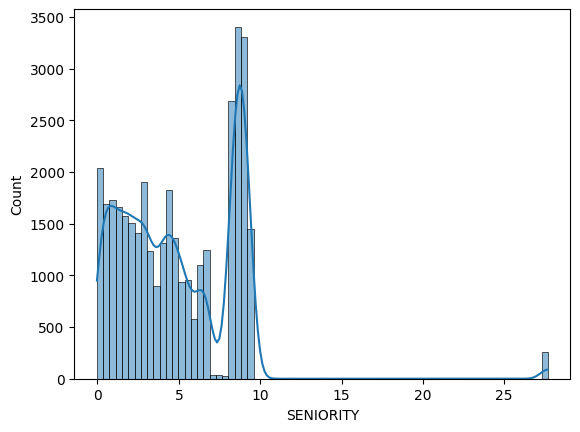

In [80]:
sns.histplot(CUSTOMERS_INFO_OK["SENIORITY"], kde = True)

Are there any outliers?

Create missing values when seniority is bigger than 10 years, and clip negative values to 0:

In [81]:
CUSTOMERS_INFO_OK["SENIORITY"] = CUSTOMERS_INFO_OK["SENIORITY"].where(CUSTOMERS_INFO_OK["SENIORITY"] <= 10).clip(lower = 0)

## 4.3 Gather all features in a MASTER table (at the individual level)

### 4.3.1 Joins

From table CUSTOMERS_INFO_OK created below, keep `ID_INDIVIDU`, `CIVILITE`, `SEXE`, `PROFESSION`, `CATEGORIE_PROF`, `DATE_CREATION_CARTE`, `MANAGING_STORE`, `AGE`, `SENIORITY`.

Join with `SHARE_MANAGING_STORE`, `NB_GIFTS`, `DIVERS_STORE`, `DIVERS_LINE`, `DIVERS_FAM`, `RECENCY`, `FREQUENCY`.

In [82]:
MASTER = CUSTOMERS_INFO_OK[[
    'ID_INDIVIDU', 'CIVILITE', 'SEXE', 'PROFESSION', 'CATEGORIE_PROF',
    'DATE_CREATION_CARTE', 'MANAGING_STORE', 'AGE', 'SENIORITY'
]]

In [83]:
MASTER = MASTER.merge(SHARE_MANAGING_STORE, on = 'ID_INDIVIDU', how = 'left')

In [84]:
MASTER = MASTER.merge(NB_GIFTS, on = 'ID_INDIVIDU', how = 'left')

In [85]:
MASTER = MASTER.merge(DIVERS_STORE, on = 'ID_INDIVIDU', how = 'left')

In [86]:
MASTER = MASTER.merge(DIVERS_LINE, on = 'ID_INDIVIDU', how = 'left')
MASTER = MASTER.merge(DIVERS_FAM, on = 'ID_INDIVIDU', how = 'left')

In [87]:
MASTER = MASTER.merge(RECENCY, on = 'ID_INDIVIDU', how = 'left')

In [88]:
MASTER = MASTER.merge(FREQUENCY, on = 'ID_INDIVIDU', how = 'left')

In [89]:
print(MASTER.shape[0])
print(MASTER['ID_INDIVIDU'].nunique())

36157
36157


There should be 36 157 rows, with the exact same number of individuals (since we have agregated data at the INDIVIDU level!)

### 4.3.2 Individuals without receipts

In [90]:
MASTER.isnull().sum()

ID_INDIVIDU                  0
CIVILITE                     0
SEXE                         0
PROFESSION               36157
CATEGORIE_PROF           14715
DATE_CREATION_CARTE          0
MANAGING_STORE               0
AGE                       2675
SENIORITY                  258
SHARE_MANAGING_STORE     23713
NB_GIFTS                 28342
NB_STORES                23713
NB_LINES                 23713
NB_FAMILIES              23713
LAST_PURCHASE            23713
RECENCY                  23713
NB_VISITS                23713
CUMUL_VALUE              23713
AVG_VISIT_VALUE          23713
AVG_NB_PRODUCTS_VISIT    23713
dtype: int64

A lot of customers have missing values concerning the purchase features. Check that they are indeed not present in the receipts table from the beginning:

In [91]:
MASTER[MASTER['RECENCY'].isnull()].head(1)

,ID_INDIVIDU,CIVILITE,SEXE,PROFESSION,CATEGORIE_PROF,DATE_CREATION_CARTE,MANAGING_STORE,AGE,SENIORITY,SHARE_MANAGING_STORE,NB_GIFTS,NB_STORES,NB_LINES,NB_FAMILIES,LAST_PURCHASE,RECENCY,NB_VISITS,CUMUL_VALUE,AVG_VISIT_VALUE,AVG_NB_PRODUCTS_VISIT
1,27,3,2,NaN,3.0,2007-08-08,942,49.0,9.071233,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN


In [92]:
RECEIPTS_INFO[RECEIPTS_INFO.ID_INDIVIDU == 27]

,DATE_ACHAT,EAN,ID_INDIVIDU,ID_FOYER,CODE_LIGNE,TYPE_LIGNE,NUM_TICKET,QUANTITE,PRIX_AP_REMISE,REMISE,REMISE_VALEUR,CODE_BOUTIQUE,ID_ARTICLE,ID_MODELE,ID_OPTION,MODELE,OPTION_PTT,COLORIS,POSITION,GRILLE


Indeed, these customers have no receipts so we are not going to consider them in the RFM segmentation. They can be prospects, inactive customers (last purchase <1 year) or very recent customer (last purchase > 31/08/2016).

For the RFM segmentation we exclude inactive customers on the year of study.

In [93]:
MASTER_RFM = MASTER[MASTER['NB_VISITS'].notnull()].copy()

In [94]:
MASTER_RFM.head()

,ID_INDIVIDU,CIVILITE,SEXE,PROFESSION,CATEGORIE_PROF,DATE_CREATION_CARTE,MANAGING_STORE,AGE,SENIORITY,SHARE_MANAGING_STORE,NB_GIFTS,NB_STORES,NB_LINES,NB_FAMILIES,LAST_PURCHASE,RECENCY,NB_VISITS,CUMUL_VALUE,AVG_VISIT_VALUE,AVG_NB_PRODUCTS_VISIT
0,4,0,0,NaN,NaN,1989-01-01,751,NaN,NaN,0.0,1.0,4.0,3.0,4.0,2016-07-23,39.0,6.0,475.0,79.166667,2.166667
9,91,2,2,NaN,2.0,2007-08-31,312,62.0,9.008219,1.0,NaN,1.0,1.0,3.0,2016-04-10,143.0,1.0,112.0,112.000000,3.000000
10,99,2,2,NaN,2.0,2007-10-10,312,46.0,8.898630,0.0,1.0,1.0,2.0,5.0,2016-05-28,95.0,3.0,177.0,59.000000,2.333333
87,557,3,2,NaN,NaN,2007-05-14,753,57.0,9.306849,1.0,15.0,1.0,3.0,7.0,2016-06-27,65.0,6.0,272.0,45.333333,3.666667
208,1396,3,2,NaN,NaN,2007-12-19,920,43.0,8.706849,0.0,5.0,4.0,2.0,8.0,2016-07-02,60.0,8.0,876.0,109.500000,4.750000


In [95]:
len(MASTER_RFM)

12444

In [96]:
MASTER_RFM.isnull().sum()

ID_INDIVIDU                  0
CIVILITE                     0
SEXE                         0
PROFESSION               12444
CATEGORIE_PROF            5815
DATE_CREATION_CARTE          0
MANAGING_STORE               0
AGE                        904
SENIORITY                   11
SHARE_MANAGING_STORE         0
NB_GIFTS                  4629
NB_STORES                    0
NB_LINES                     0
NB_FAMILIES                  0
LAST_PURCHASE                0
RECENCY                      0
NB_VISITS                    0
CUMUL_VALUE                  0
AVG_VISIT_VALUE              0
AVG_NB_PRODUCTS_VISIT        0
dtype: int64

There should be 12 444 INDIVIDU now.

---

Fill missing values with 0 for NB_GIFTS:

In [97]:
MASTER_RFM['NB_GIFTS'] = MASTER_RFM['NB_GIFTS'].fillna(0)

# 5 Creation of the "RFM" segmentation

## 5.1 Distribution of Monetary value

The column is `CUMUL_VALUE`.

Use `describe` and `distplot`.

In [98]:
MASTER_RFM.CUMUL_VALUE.describe()

count    12444.000000
mean       263.170604
std        242.078243
min          0.000000
25%        125.000000
50%        194.000000
75%        324.000000
max       3640.000000
Name: CUMUL_VALUE, dtype: float64

<Axes: xlabel='CUMUL_VALUE', ylabel='Count'>

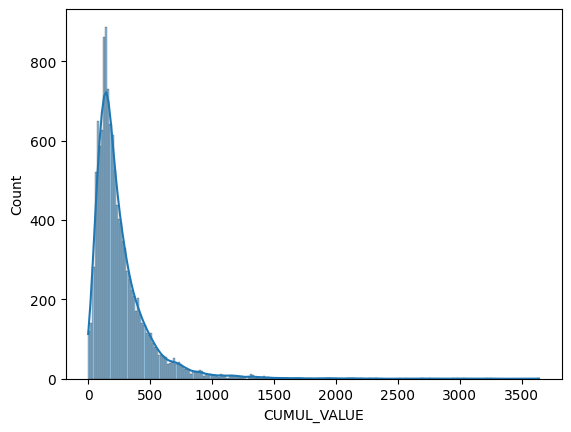

In [99]:
sns.histplot(MASTER_RFM["CUMUL_VALUE"], kde = True)

We have customers with a 0 cumulative value. Let's look at them.

In [100]:
MASTER_RFM[MASTER_RFM.CUMUL_VALUE == 0].head()

,ID_INDIVIDU,CIVILITE,SEXE,PROFESSION,CATEGORIE_PROF,DATE_CREATION_CARTE,MANAGING_STORE,AGE,SENIORITY,SHARE_MANAGING_STORE,NB_GIFTS,NB_STORES,NB_LINES,NB_FAMILIES,LAST_PURCHASE,RECENCY,NB_VISITS,CUMUL_VALUE,AVG_VISIT_VALUE,AVG_NB_PRODUCTS_VISIT
471,2976,3,2,NaN,14.0,2007-10-26,942,37.0,8.854795,1.0,2.0,1.0,0.0,0.0,2016-02-05,208.0,1.0,0.0,0.0,2.0
963,6195,3,2,NaN,2.0,2008-02-13,941,37.0,8.553425,0.5,2.0,2.0,1.0,1.0,2016-08-08,23.0,2.0,0.0,0.0,1.0
1220,7992,3,2,NaN,6.0,2007-09-05,941,44.0,8.994521,1.0,2.0,1.0,1.0,1.0,2016-04-06,147.0,2.0,0.0,0.0,1.0
1626,10683,3,2,NaN,3.0,2008-05-25,750,49.0,8.273973,1.0,1.0,1.0,1.0,1.0,2016-08-03,28.0,1.0,0.0,0.0,1.0
2497,16687,3,2,NaN,6.0,2007-07-07,331,49.0,9.158904,0.0,1.0,1.0,0.0,0.0,2016-03-21,163.0,1.0,0.0,0.0,1.0


In [101]:
RECEIPTS_INFO_RFM[RECEIPTS_INFO_RFM.ID_INDIVIDU == 6195]

,DATE_ACHAT,EAN,ID_INDIVIDU,ID_FOYER,NUM_TICKET,QUANTITE,PRIX_AP_REMISE,CODE_BOUTIQUE,ID_ARTICLE,ID_MODELE,ID_OPTION,MODELE,OPTION_PTT,COLORIS,POSITION,GRILLE,Ligne,Famille,REGIONS,CENTRE_VILLE,TYPE_MAGASIN,REMISE_VALUE,PRIX_INITIAL,REMISE_PCT,Favorites,Access,PLV,Gift,PRICE
1480,2016-05-17,3585211909450,6195,4914,7,1,0,770,64564.0,7.0,15101.0,FAVO,TASB7,13.0,1.0,5.0,NaN,NaN,Paris,Centre Commercial,Succursale,0.0,0.0,100.0,1,0,0,1,0
1487,2016-08-08,3585211915857,6195,4914,10,1,0,941,66361.0,66.0,11019.0,540,FAVOR,3201.0,1.0,5.0,Bain,Bain_Beachwear,Paris,Centre Commercial,Succursale,0.0,0.0,100.0,0,0,0,1,0


This customer came only for products with no value...

In [102]:
len(MASTER_RFM[MASTER_RFM.CUMUL_VALUE == 0])

104

Few customers are concerned. We drop them of the MASTER_RFM table.

In [103]:
MASTER_RFM = MASTER_RFM[MASTER_RFM.CUMUL_VALUE > 0].copy()

In [104]:
len(MASTER_RFM)

12340

## 5.2 Distribution of Frequency

In [105]:
MASTER_RFM.NB_VISITS.describe()

count    12340.000000
mean         2.495705
std          2.312851
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         32.000000
Name: NB_VISITS, dtype: float64

<Axes: xlabel='NB_VISITS', ylabel='Count'>

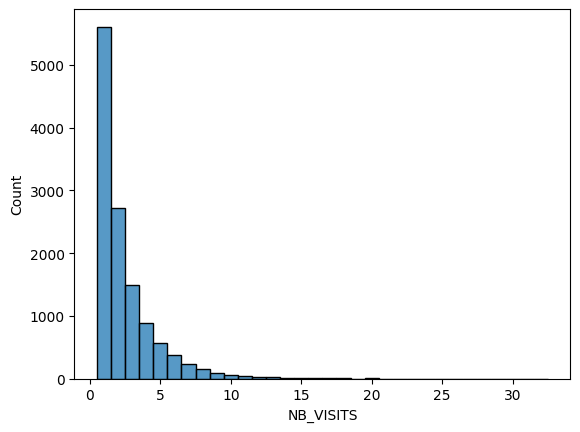

In [106]:
sns.histplot(MASTER_RFM["NB_VISITS"], discrete = True)

## 5.3 Distribution of Recency

In [107]:
MASTER_RFM.RECENCY.describe()

count    12340.000000
mean       128.094733
std         97.660819
min          0.000000
25%         49.000000
50%        101.000000
75%        196.000000
max        365.000000
Name: RECENCY, dtype: float64

<Axes: xlabel='RECENCY', ylabel='Count'>

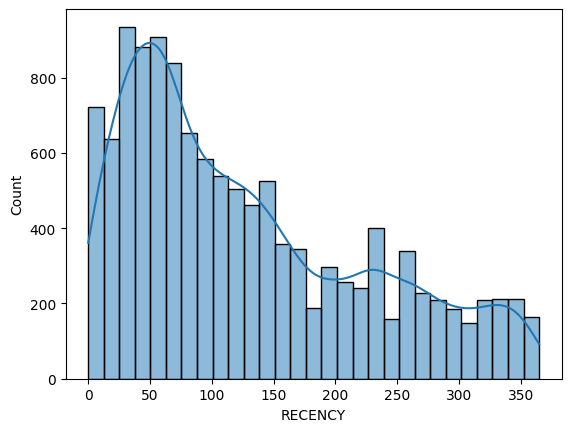

In [108]:
sns.histplot(MASTER_RFM["RECENCY"], kde = True)

## 5.4 Identifying new customers

Recall that we only look at 1 year of purchase history for customers. If the seniority is less than 1 year, what kind of customers are they? We want to create a variable to identify them:

In [109]:
# New customer if seniority < 1 year
MASTER_RFM["TOP_NEW"] = (MASTER_RFM["SENIORITY"] < 1).astype(int)

In [110]:
# Number of new customers
sum(MASTER_RFM["TOP_NEW"])

4694

There should be 4694 new customers.

## 5.5 Determine thresholds in order to split them in low/medium/high groups

Compute quantiles at 33% and 67% for the 3 three variables that we will use to build the RFM.

In [111]:
MASTER_RFM[['CUMUL_VALUE', 'NB_VISITS', 'RECENCY']].quantile([0.33, 0.67])

,CUMUL_VALUE,NB_VISITS,RECENCY
0.33,144.0,1.0,62.0
0.67,273.0,2.0,154.0


So we can propose the following thresholds:

MONETARY VALUE/ CUMUL VALUE:
- low if less than 140€
- medium if between 140€ and 280€
- high if more than 280€

FREQUENCY/ NB VISITS:
- low if 1 visit on the period
- medium if 2 visits on the period
- high if 3 visits or more on the period

RECENCY: 
- low if last purchase more than 150 days ago (5 months)
- medium if last purchase between 60 and 150 days ago (2 and 5 months)
- high if last purchase less than 60 days ago (2 months)

**Convention retenue pour la récence :** « High » correspond à un dernier achat datant de **60 jours ou moins** (borne incluse). C'est la convention qui redonne exactement les volumes de référence (avec une borne stricte `< 60` : Top 1 921, Good 1 627 au lieu de 1 964 et 1 584).

In [112]:
min_money = 140
max_money = 280
min_frequency = 1
max_frequency = 3
min_recency = 60
max_recency = 150

Create new / high / med / low levels for the 3 indicators:

In [113]:
MASTER_RFM["RECENCY_level"] = np.where(
    MASTER_RFM["TOP_NEW"] == 1,
    'New',
    np.where(
        MASTER_RFM["RECENCY"] > max_recency,
        'Low',
        np.where(
            MASTER_RFM["RECENCY"] <= min_recency,
            'High',
            'Medium'
        )
    )
)

In [114]:
MASTER_RFM["FREQUENCY_level"] = np.where(
    MASTER_RFM["TOP_NEW"] == 1,
    'New',
    np.where(
        MASTER_RFM["NB_VISITS"] <= min_frequency,
        'Low',
        np.where(
            MASTER_RFM["NB_VISITS"] >= max_frequency,
            'High',
            'Medium'
        )
    )
)

In [115]:
MASTER_RFM["MONEY_level"] = np.where(
    MASTER_RFM["TOP_NEW"] == 1,
    'New',
    np.where(
        MASTER_RFM["CUMUL_VALUE"] < min_money,
        'Low',
        np.where(
            MASTER_RFM["CUMUL_VALUE"] > max_money,
            'High',
            'Medium'
        )
    )
)

Check that the Low/Medium/High classes are quite well balanced. If not, try to change the thresholds.

In [116]:
MASTER_RFM[["RECENCY_level", "ID_INDIVIDU"]].groupby("RECENCY_level").count()

,ID_INDIVIDU
RECENCY_level,
High,2570
Low,2588
Medium,2488
New,4694


In [117]:
MASTER_RFM[["FREQUENCY_level", "ID_INDIVIDU"]].groupby("FREQUENCY_level").count()

,ID_INDIVIDU
FREQUENCY_level,
High,3079
Low,2886
Medium,1681
New,4694


In [118]:
MASTER_RFM[["MONEY_level", "ID_INDIVIDU"]].groupby("MONEY_level").count()

,ID_INDIVIDU
MONEY_level,
High,2541
Low,2774
Medium,2331
New,4694


Create FM segmentation based on splits seen in class:

You can start by creating boolean vectors based on recency / frequency / money.

In [119]:
# Grille FM du cours (slide 24)
F = MASTER_RFM["FREQUENCY_level"]
M = MASTER_RFM["MONEY_level"]

cond_LowFM = (
    ((F == 'Low') & (M == 'Low'))
    | ((F == 'Low') & (M == 'Medium'))
    | ((F == 'Medium') & (M == 'Low'))
)

cond_HighFM = (
    ((F == 'Medium') & (M == 'High'))
    | ((F == 'High') & (M == 'Medium'))
    | ((F == 'High') & (M == 'High'))
)

cond_MediumFM = (
    (F != 'New') & ~cond_LowFM & ~cond_HighFM
)

Create FM segmentation:

In [120]:
MASTER_RFM["FM_SEG"] = np.where(
    MASTER_RFM["TOP_NEW"] == 1,
    'New',
    np.where(
        cond_LowFM,
        'Low',
        np.where(
            cond_HighFM,
            'High',
            'Medium'
        )
    )
)

In [121]:
MASTER_RFM[["FM_SEG", "ID_INDIVIDU"]].groupby("FM_SEG").count()

,ID_INDIVIDU
FM_SEG,
High,3231
Low,3292
Medium,1123
New,4694


In [122]:
MASTER_RFM[["FM_SEG", "ID_INDIVIDU"]].count()

FM_SEG         12340
ID_INDIVIDU    12340
dtype: int64

Create RFM segmentation based on splits seen in class:

You can start by creating boolean vectors based on recency / frequency / money.

In [123]:
# Consolidation du cours (slide 26)
R = MASTER_RFM["RECENCY_level"]
cond_FM_MedHigh = cond_MediumFM | cond_HighFM

cond_Top = cond_FM_MedHigh & (R == 'High')        # RFM 8, 9
cond_Good = cond_FM_MedHigh & (R == 'Medium')     # RFM 5, 6
cond_Decel = cond_FM_MedHigh & (R == 'Low')       # RFM 2, 3
cond_Small = cond_LowFM & R.isin(['High', 'Medium'])  # RFM 4, 7
cond_Weak = cond_LowFM & (R == 'Low')             # RFM 1

In [124]:
MASTER_RFM["RFM_SEG"] = np.where(
    cond_Top,
    '5 Top',
    np.where(
        cond_Good,
        '4 Good',
        np.where(
            cond_Decel,
            '3 Decel',
            np.where(
                cond_Small,
                '2 Small',
                np.where(
                    cond_Weak,
                    '1 Weak',
                    MASTER_RFM.FM_SEG
)))))

In [125]:
MASTER_RFM[["RFM_SEG", "ID_INDIVIDU"]].groupby("RFM_SEG").count()

,ID_INDIVIDU
RFM_SEG,
1 Weak,1782
2 Small,1510
3 Decel,806
4 Good,1584
5 Top,1964
New,4694


It can be different for you depending on the thresholds you use, but here are numbers with coherent thresholds, for reference:
| Customers | Volume |
| ----- | ------ |
| New   | 4694  |
| Weak  | 1782  |
| Small | 1510  |
| Decel | 806   |
| Good  | 1584  |
| Top   | 1964  |